# Chapter 28: What Is Happening Right Now?

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** use one simple motion, a position s = t squared in meters and seconds, to see why an average rate needs two times, and how shrinking the interval (without ever making it zero) points to a rate at a single moment. You will also see a corner where that rate does not exist.

The code cells are optional reading. You can skip them: the results and the pictures are shown right below each one. If you are curious, read a code cell like a recipe, one line at a time. Every number is built from steps you can check with a calculator.

In [1]:
# Setup: numpy and matplotlib only. Nothing here needs to be understood to follow along.
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

INK, TEAL, TERRA, NAVY, GOLD, GREY, LIGHT = "#222222", "#1b7f79", "#c0562f", "#1f3a5f", "#b8860b", "#777777", "#d9d9d9"
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.grid": True, "grid.alpha": 0.25})

def show_fig(title=None):
    if title:
        plt.title(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def num(q, digits=4):
    """Exact fraction shown as a short decimal (trailing zeros dropped)."""
    text = f"{float(Fraction(q)):.{digits}f}"
    return text.rstrip("0").rstrip(".") if "." in text else text

def par(q):
    t = num(q)
    return f"({t})" if t.startswith("-") else t

def s(t):
    return Fraction(t) ** 2

## 1. An average rate needs two times

**Question in plain words:** Between 2 seconds and another time, how fast was the position changing on average?

**Equations from the chapter:**

$$\frac{f(b) - f(a)}{b - a} \qquad \text{slope} = \frac{\text{vertical change}}{\text{horizontal change}}$$

**What the symbols mean:** $a$ and $b$ are two input times, here $a = 2$ seconds. $f(b) - f(a)$ is the change in position in meters, and $b - a$ is the change in time in seconds, so the quotient is in meters per second. Our motion is $s = t^2$.

In [2]:
a, b = Fraction(2), Fraction(3)
rate = (s(b) - s(a)) / (b - a)

print("Position model: s = t^2, so s(2) = 4 meters and s(3) = 9 meters.")
print()
print(f"[s({num(b)}) - s(2)]/({num(b)} - 2)")
print(f"  = ({num(s(b))} - 4)/{par(b - a)}")
print(f"  = {par(s(b) - 4)}/{par(b - a)}")
print(f"  = {num(rate)} meters per second")
print()
print("Other second times from the reader's menu:")
for bb in ["3", "2.5", "1", "2"]:
    bq = Fraction(bb)
    if bq == a:
        print("  b = 2: [s(2) - s(2)]/(2 - 2) = 0/0, undefined (the interval has zero width)")
    else:
        r_ = (s(bq) - s(a)) / (bq - a)
        print(f"  b = {bb}: ({num(s(bq))} - 4)/({num(bq)} - 2) = {par(s(bq) - 4)}/{par(bq - a)} = {num(r_)} m/s")
print()
print("Note b = 1: both changes are negative, so the quotient is still positive.")

Position model: s = t^2, so s(2) = 4 meters and s(3) = 9 meters.

[s(3) - s(2)]/(3 - 2)
  = (9 - 4)/1
  = 5/1
  = 5 meters per second

Other second times from the reader's menu:
  b = 3: (9 - 4)/(3 - 2) = 5/1 = 5 m/s
  b = 2.5: (6.25 - 4)/(2.5 - 2) = 2.25/0.5 = 4.5 m/s
  b = 1: (1 - 4)/(1 - 2) = (-3)/(-1) = 3 m/s
  b = 2: [s(2) - s(2)]/(2 - 2) = 0/0, undefined (the interval has zero width)

Note b = 1: both changes are negative, so the quotient is still positive.


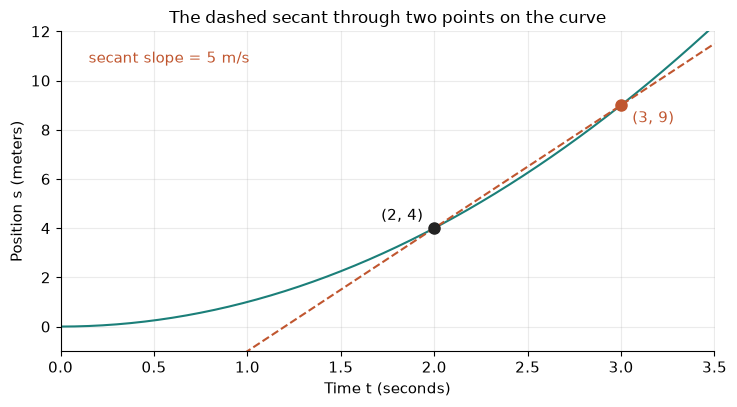

In [3]:
fig, ax = plt.subplots()
ts = np.linspace(0, 3.5, 141)
ax.plot(ts, ts ** 2, color=TEAL)
xs = np.array([0.0, 3.5])
ax.plot(xs, 4 + float(rate) * (xs - 2), linestyle="dashed", color=TERRA)
ax.plot([2], [4], "o", color=INK, markersize=8)
ax.plot([3], [9], "o", color=TERRA, markersize=8)
ax.annotate("(2, 4)", (2, 4), xytext=(-8, 6), textcoords="offset points", ha="right")
ax.annotate("(3, 9)", (3, 9), xytext=(8, -4), textcoords="offset points", color=TERRA, va="top")
ax.text(0.15, 11.2, f"secant slope = {num(rate)} m/s", color=TERRA, va="top")
ax.set_xlim(0, 3.5); ax.set_ylim(-1, 12)
ax.set_xlabel("Time t (seconds)"); ax.set_ylabel("Position s (meters)")
show_fig("The dashed secant through two points on the curve")

**What this shows.** The two points on the curve fix a secant line, and its slope is the average rate. Everything that happened in between is squeezed into that one number. When someone reports an average rate, ask for the two endpoints: a different interval can give a different rate for the same motion.

**Where it stops working.** If both endpoints are the same time, the denominator is zero and there is no rate at all. A rate at one instant needs a different idea, which the next demonstration builds.

## 2. Shrink the interval without making it zero

**Question in plain words:** What do the average rates near $t = 2$ do as the interval gets shorter from either side?

**Equations from the chapter:**

$$\frac{s(2+h) - s(2)}{h} \qquad = \frac{h(4+h)}{h} \qquad = 4 + h$$

**What the symbols mean:** $h$ is the interval length in seconds and is never 0. Positive $h$ looks later than $t = 2$; negative $h$ looks earlier. The quotient is the average rate over that interval.

In [4]:
h = Fraction(1, 10)
later = s(2 + h)
q = (later - 4) / h

print(f"Take h = {num(h)}.")
print(f"  second time: 2 + {par(h)} = {num(2 + h)} seconds")
print(f"  s(2 + h) = {num(2 + h)}^2 = {num(later)}")
print(f"  quotient = ({num(later)} - 4)/{par(h)} = {par(later - 4)}/{par(h)} = {num(q)}")
print(f"  simplified rule: 4 + h = 4 + {par(h)} = {num(4 + h)}")
print("The cancellation h(4 + h)/h = 4 + h is allowed because h is not 0.")
print()
print("Why the simplification works: (2 + h)^2 - 4 = 4 + 4h + h^2 - 4 = 4h + h^2 = h(4 + h).")
print()
print("Other steps from the reader's menu (the rate is 4 + h every time):")
for hh in ["0.5", "0.1", "-0.1", "-0.5"]:
    hq = Fraction(hh)
    qq = (s(2 + hq) - 4) / hq
    print(f"  h = {hh}: (({num(2 + hq)})^2 - 4)/{par(hq)} = ({num(s(2 + hq))} - 4)/{par(hq)} = {num(qq)}   and 4 + {par(hq)} = {num(4 + hq)}")
print("Smaller steps still: h = 0.01 gives 4.01, h = 0.001 gives 4.001. The rates head toward 4 from both sides.")

Take h = 0.1.
  second time: 2 + 0.1 = 2.1 seconds
  s(2 + h) = 2.1^2 = 4.41
  quotient = (4.41 - 4)/0.1 = 0.41/0.1 = 4.1
  simplified rule: 4 + h = 4 + 0.1 = 4.1
The cancellation h(4 + h)/h = 4 + h is allowed because h is not 0.

Why the simplification works: (2 + h)^2 - 4 = 4 + 4h + h^2 - 4 = 4h + h^2 = h(4 + h).

Other steps from the reader's menu (the rate is 4 + h every time):
  h = 0.5: ((2.5)^2 - 4)/0.5 = (6.25 - 4)/0.5 = 4.5   and 4 + 0.5 = 4.5
  h = 0.1: ((2.1)^2 - 4)/0.1 = (4.41 - 4)/0.1 = 4.1   and 4 + 0.1 = 4.1
  h = -0.1: ((1.9)^2 - 4)/(-0.1) = (3.61 - 4)/(-0.1) = 3.9   and 4 + (-0.1) = 3.9
  h = -0.5: ((1.5)^2 - 4)/(-0.5) = (2.25 - 4)/(-0.5) = 3.5   and 4 + (-0.5) = 3.5
Smaller steps still: h = 0.01 gives 4.01, h = 0.001 gives 4.001. The rates head toward 4 from both sides.


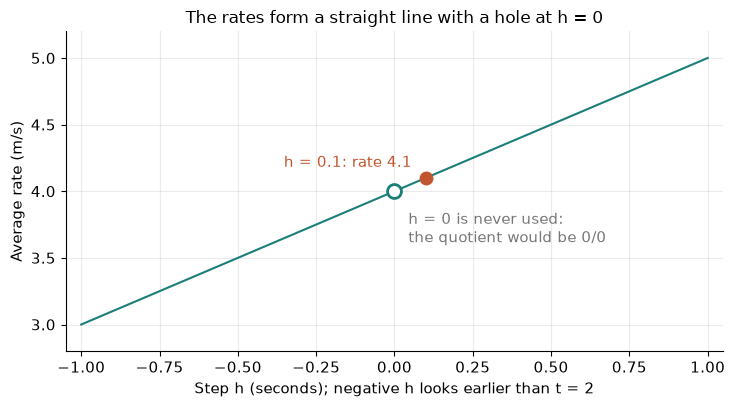

In [5]:
hs = np.linspace(-1, 1, 81)
fig, ax = plt.subplots()
ax.plot(hs, 4 + hs, color=TEAL)
ax.plot([0], [4], "o", markersize=10, markerfacecolor="white", markeredgecolor=TEAL, markeredgewidth=2, zorder=5)
ax.annotate("h = 0 is never used:\nthe quotient would be 0/0", (0, 4), xytext=(10, -14), textcoords="offset points", color=GREY, va="top")
ax.plot([float(h)], [float(q)], "o", color=TERRA, markersize=9, zorder=6)
ax.annotate(f"h = {num(h)}: rate {num(q)}", (float(h), float(q)), xytext=(-10, 8), textcoords="offset points", ha="right", color=TERRA)
ax.set_xlim(-1.05, 1.05); ax.set_ylim(2.8, 5.2)
ax.set_xlabel("Step h (seconds); negative h looks earlier than t = 2")
ax.set_ylabel("Average rate (m/s)")
show_fig("The rates form a straight line with a hole at h = 0")

**What this shows.** For every nonzero $h$ the quotient simplifies to $4 + h$, so the rates lie on a straight line with a hole at $h = 0$. From both sides they head toward 4. When a calculation needs a rate at an instant, keep the interval nonzero, simplify, and only then ask what the result approaches.

**Where it stops working.** Cancelling $h$ is legal only because $h$ is not 0. Substituting $h = 0$ into the original quotient gives $0/0$, which is not a rate. The claim also applies only to this motion, $s = t^2$ near $t = 2$.

## 3. Nearby secants approach a direction

**Question in plain words:** As the second point slides toward $(2, 4)$, what happens to the secant and to a simple estimate of the position change?

**Equations from the chapter:**

$$s = t^2 \qquad 4(0.1) = 0.4$$

**What the symbols mean:** The secant joins $(2, 4)$ to $(2+h, (2+h)^2)$. Its slope is $4 + h$. The tangent estimate of the position change is $4$ times $h$. The discrepancy is how far that estimate is from the exact change.

In [6]:
h = Fraction(1, 10)
exact = s(2 + h) - 4
estimate = 4 * h
print(f"Interval length h = {num(h)} s")
print(f"  secant slope: 4 + {num(h)} = {num(4 + h)} m/s")
print(f"  exact change: {num(2 + h)}^2 - 4 = {num(s(2 + h))} - 4 = {num(exact)} m")
print(f"  tangent estimate: 4({num(h)}) = {num(estimate)} m")
print(f"  discrepancy: {num(exact)} - {num(estimate)} = {num(exact - estimate)} m")
print()
print("Other intervals from the reader's menu:")
for hh in ["1", "0.5", "0.1", "0.01"]:
    hq = Fraction(hh)
    ex = s(2 + hq) - 4
    print(f"  h = {hh}: exact {num(2 + hq)}^2 - 4 = {num(ex)}; estimate 4({hh}) = {num(4 * hq)}; discrepancy = {num(ex - 4 * hq)}   (h squared = {num(hq * hq, 6)})")

Interval length h = 0.1 s
  secant slope: 4 + 0.1 = 4.1 m/s
  exact change: 2.1^2 - 4 = 4.41 - 4 = 0.41 m
  tangent estimate: 4(0.1) = 0.4 m
  discrepancy: 0.41 - 0.4 = 0.01 m

Other intervals from the reader's menu:
  h = 1: exact 3^2 - 4 = 5; estimate 4(1) = 4; discrepancy = 1   (h squared = 1)
  h = 0.5: exact 2.5^2 - 4 = 2.25; estimate 4(0.5) = 2; discrepancy = 0.25   (h squared = 0.25)
  h = 0.1: exact 2.1^2 - 4 = 0.41; estimate 4(0.1) = 0.4; discrepancy = 0.01   (h squared = 0.01)
  h = 0.01: exact 2.01^2 - 4 = 0.0401; estimate 4(0.01) = 0.04; discrepancy = 0.0001   (h squared = 0.0001)


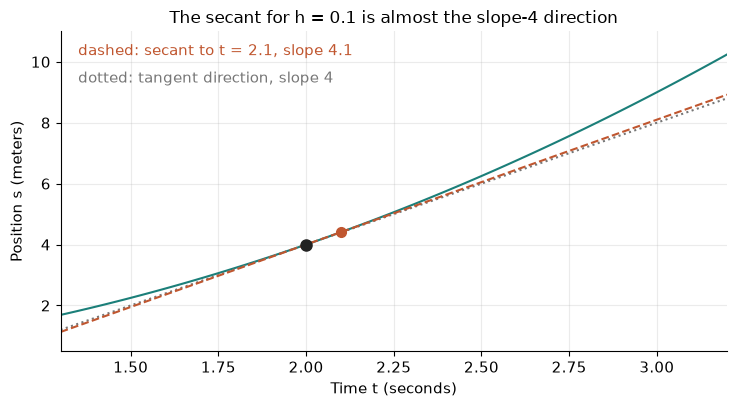

In [7]:
ts = np.linspace(1.3, 3.2, 120)
fig, ax = plt.subplots()
ax.plot(ts, ts ** 2, color=TEAL)
xs = np.array([1.3, 3.2])
ax.plot(xs, 4 + 4 * (xs - 2), ":", color=GREY)
ax.plot(xs, 4 + float(4 + h) * (xs - 2), linestyle="dashed", color=TERRA)
ax.plot([2], [4], "o", color=INK, markersize=8, zorder=5)
ax.plot([float(2 + h)], [float(s(2 + h))], "o", color=TERRA, markersize=7, zorder=6)
ax.text(1.35, 10.6, f"dashed: secant to t = {num(2 + h)}, slope {num(4 + h)}", color=TERRA, va="top")
ax.text(1.35, 9.7, "dotted: tangent direction, slope 4", color=GREY, va="top")
ax.set_xlim(1.3, 3.2); ax.set_ylim(0.5, 11)
ax.set_xlabel("Time t (seconds)"); ax.set_ylabel("Position s (meters)")
show_fig("The secant for h = 0.1 is almost the slope-4 direction")

**What this shows.** The base point $(2, 4)$ stays fixed while the second point moves in, and the dashed secant turns toward the dotted line of slope 4. The discrepancy is exactly $h^2$ here, so shrinking $h$ tenfold shrinks the discrepancy a hundredfold. Near a point where a rate exists, change is roughly the rate times the small step.

**Where it stops working.** The word *roughly* is honest only for small steps: at $h = 1$ the estimate is off by a whole meter. This is the model $s = t^2$ near $t = 2$ only.

## 4. A corner has no single rate

**Question in plain words:** At the corner of $|x|$, do the slopes from the left and from the right agree?

**Equations from the chapter:**

$$\frac{g(h) - g(0)}{h} = \frac{|h|}{h} = 1 \qquad \frac{|h|}{h} = -1$$

**What the symbols mean:** $g(x) = |x|$ is the distance of $x$ from 0. $h$ is a nonzero step from 0, and $|h|/h$ is the slope of the secant from $(0, 0)$ to $(h, |h|)$. The first value, 1, is for positive $h$; the second, $-1$, is for negative $h$.

In [8]:
h = Fraction(1, 100)
q = abs(h) / h
print(f"Take h = {num(h, 2)}.")
print(f"  g(h) - g(0) = |{num(h, 2)}| - 0 = {num(abs(h), 2)}")
print(f"  quotient |h|/h = {num(abs(h), 2)}/{par(h)} = {num(q)}")
print()
print("Both sides, from the reader's menu:")
for hh in ["0.5", "0.01", "-0.01", "-0.5"]:
    hq = Fraction(hh)
    qq = abs(hq) / hq
    side = "right" if hq > 0 else "left"
    print(f"  h = {hh} ({side}): |{hh}|/{par(hq)} = {num(abs(hq), 2)}/{par(hq)} = {num(qq)}")
print()
print("Every right-hand quotient is 1 and every left-hand quotient is -1, however small h gets.")
print("The two sides approach different numbers, so there is no single rate at 0.")

Take h = 0.01.
  g(h) - g(0) = |0.01| - 0 = 0.01
  quotient |h|/h = 0.01/0.01 = 1

Both sides, from the reader's menu:
  h = 0.5 (right): |0.5|/0.5 = 0.5/0.5 = 1
  h = 0.01 (right): |0.01|/0.01 = 0.01/0.01 = 1
  h = -0.01 (left): |-0.01|/(-0.01) = 0.01/(-0.01) = -1
  h = -0.5 (left): |-0.5|/(-0.5) = 0.5/(-0.5) = -1

Every right-hand quotient is 1 and every left-hand quotient is -1, however small h gets.
The two sides approach different numbers, so there is no single rate at 0.


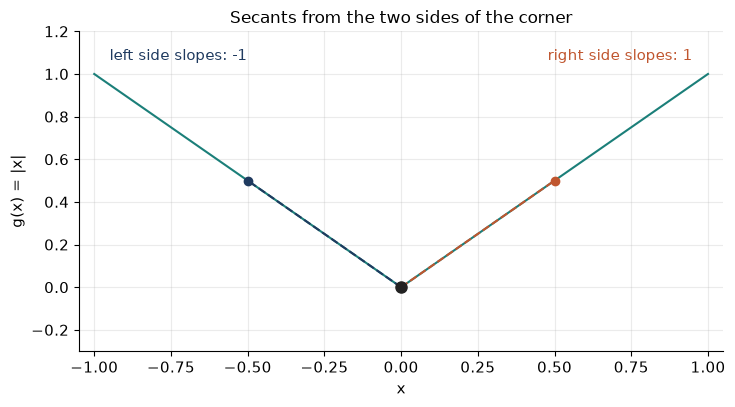

In [9]:
xs = np.linspace(-1, 1, 81)
fig, ax = plt.subplots()
ax.plot(xs, np.abs(xs), color=TEAL)
for hh, col in [(0.5, TERRA), (-0.5, NAVY)]:
    ax.plot([0, hh], [0, abs(hh)], linestyle="dashed", color=col)
    ax.plot([hh], [abs(hh)], "o", color=col)
ax.plot([0], [0], "o", color=INK, markersize=8, zorder=5)
ax.text(-0.95, 1.12, "left side slopes: -1", color=NAVY, va="top")
ax.text(0.95, 1.12, "right side slopes: 1", color=TERRA, va="top", ha="right")
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-0.3, 1.2)
ax.set_xlabel("x"); ax.set_ylabel("g(x) = |x|")
show_fig("Secants from the two sides of the corner")

**What this shows.** On the right the graph is the line $y = x$, on the left the line $y = -x$. Every right-hand quotient is 1 and every left-hand quotient is $-1$, however small $h$ gets. The sides disagree, so no single rate exists at 0. When a graph has a sharp corner, check both one-sided rates before naming a single rate.

**Where it stops working.** This is the one example $g(x) = |x|$ at 0. The function is still continuous there (no jump, no hole); it is the rate that fails, because the two sides approach different numbers.

## Practice

**1.** What is the average rate from $t = 2$ to $t = 4$?

<details><summary>Show answer</summary>

$s(4) = 16$ and $s(2) = 4$, so $\frac{16 - 4}{4 - 2} = \frac{12}{2} = 6$ meters per second.

</details>

**2.** Using $4 + h$, what is the average rate from $t = 2$ to $t = 2.01$?

<details><summary>Show answer</summary>

Here $h = 0.01$, so $4 + 0.01 = 4.01$ meters per second. Check: $s(2.01) = 4.0401$, and $\frac{4.0401 - 4}{0.01} = \frac{0.0401}{0.01} = 4.01$.

</details>

**3.** At $h = 0.5$, what are the exact change, the tangent estimate, and the discrepancy?

<details><summary>Show answer</summary>

Exact change: $2.5^2 - 4 = 6.25 - 4 = 2.25$ meters. Tangent estimate: $4(0.5) = 2$ meters. Discrepancy: $2.25 - 2 = 0.25$ meter, which is $h^2 = 0.5^2 = 0.25$.

</details>

**4.** For $g(x) = |x|$, what is $[g(h) - g(0)]/h$ at $h = -0.2$?

<details><summary>Show answer</summary>

$\frac{|-0.2|}{-0.2} = \frac{0.2}{-0.2} = -1$.

</details>